# 04 · Key findings and summary figure
Pulls the headline numbers from the saved results into one table and one summary figure for the README.
Every number below is computed from `results/`; nothing is typed in by hand.

In [1]:
import sys; sys.path.insert(0, "..")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from src.energy import *
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
ej = pd.read_csv("../data/processed/tes_by_source_EJ.csv", index_col="year")
grp = pd.read_csv("../results/group_shares_pct.csv", index_col="year")
proj = pd.read_csv("../results/projection_2030_summary.csv")
bt = pd.read_csv("../results/backtest_summary.csv")
cg = pd.read_csv("../results/cagr_by_window_pct.csv", index_col=0)
add = pd.read_csv("../results/growth_rate_vs_absolute.csv", index_col=0)
SWO, HYD = "Solar, wind and other renewables", "Hydropower"
cross = int(next(y for y in ej.index if (ej[SWO] - ej[HYD]).loc[y:].gt(0).all()))
p30 = proj[proj.year == 2030].set_index("series")

In [2]:
m = p30.index[p30.index.str.startswith("Modern")][0]; r = p30.index[p30.index.str.startswith("All")][0]
findings = pd.DataFrame({
    "Finding": [
        "Total energy supply, 1990 → 2024 (EJ)",
        "Fossil share of supply, 1990 → 2024 (%)",
        "Modern renewables share, 1990 → 2024 (%)",
        "All renewables share, 1990 → 2024 (%)",
        "CAGR 1990–2024: solar, wind & other (%)",
        "Share of all added supply from solar, wind & other (%)",
        "Year solar, wind & other permanently overtook hydropower",
        "Modern renewables share in 2030: median (90% interval) (%)",
        "All renewables share in 2030: median (90% interval) (%)"],
    "Value": [
        f"{ej.sum(axis=1).loc[1990]:.0f} → {ej.sum(axis=1).loc[2024]:.0f}",
        f"{grp.loc[1990,'Fossil']:.1f} → {grp.loc[2024,'Fossil']:.1f}",
        f"{grp.loc[1990,'Modern renewables']:.1f} → {grp.loc[2024,'Modern renewables']:.1f}",
        f"{grp.loc[1990,'Renewables']:.1f} → {grp.loc[2024,'Renewables']:.1f}",
        f"{cg.loc[SWO,'1990-2024']:.1f}",
        f"{add.loc[SWO,'Share of all added supply (%)']:.1f}",
        f"{cross}",
        f"{p30.loc[m,'median']:.1f} ({p30.loc[m,'lo90']:.1f}–{p30.loc[m,'hi90']:.1f})",
        f"{p30.loc[r,'median']:.1f} ({p30.loc[r,'lo90']:.1f}–{p30.loc[r,'hi90']:.1f})"]})
findings.to_csv("../results/key_findings.csv", index=False)
findings

,Finding,Value
0,"Total energy supply, 1990 → 2024 (EJ)",364 → 650
1,"Fossil share of supply, 1990 → 2024 (%)",81.8 → 80.5
2,"Modern renewables share, 1990 → 2024 (%)",2.5 → 6.1
3,"All renewables share, 1990 → 2024 (%)",12.1 → 14.8
4,"CAGR 1990–2024: solar, wind & other (%)",8.3
5,"Share of all added supply from solar, wind & o...",7.6
6,"Year solar, wind & other permanently overtook ...",2021
7,Modern renewables share in 2030: median (90% i...,7.9 (7.0–9.1)
8,All renewables share in 2030: median (90% inte...,16.2 (14.7–17.9)


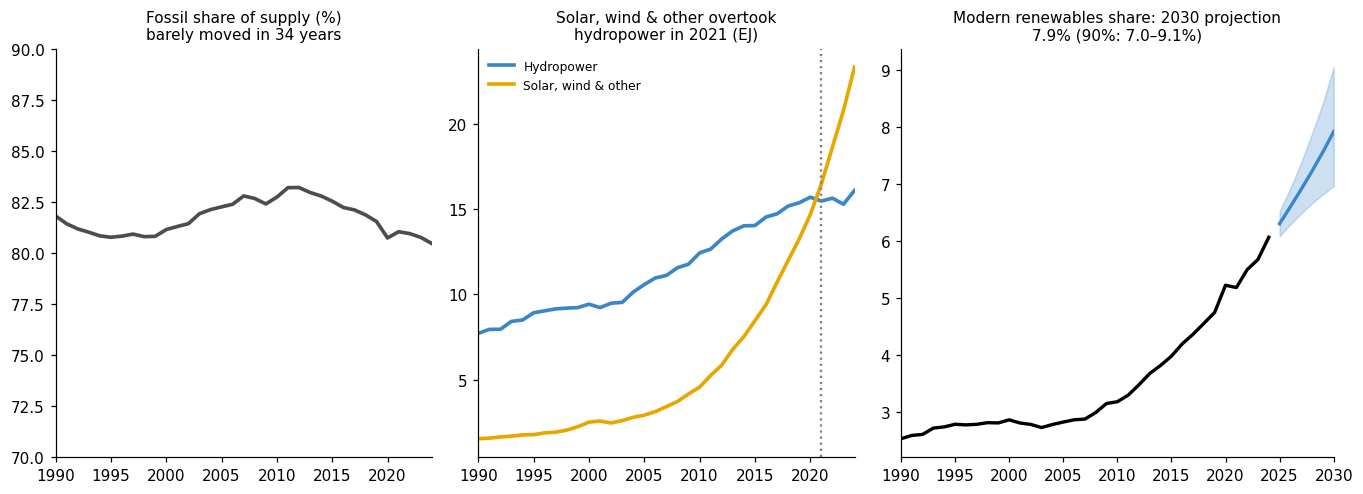

In [3]:
fig = plt.figure(figsize=(12.5, 4.6)); gs = fig.add_gridspec(1, 3, width_ratios=[1, 1, 1.15])
ax1 = fig.add_subplot(gs[0]); ax2 = fig.add_subplot(gs[1]); ax3 = fig.add_subplot(gs[2])
# 1 fossil share barely moved
ax1.plot(grp.index, grp["Fossil"], color="#4d4d4d", lw=2.4); ax1.set_ylim(70, 90)
ax1.set(title="Fossil share of supply (%)\nbarely moved in 34 years", xlim=(1990, 2024))
# 2 crossover
ax2.plot(ej.index, ej[HYD], color="#3a86c8", lw=2.4, label="Hydropower")
ax2.plot(ej.index, ej[SWO], color="#e6a800", lw=2.4, label="Solar, wind & other")
ax2.axvline(cross, color="grey", ls=":"); ax2.legend(frameon=False, fontsize=8, loc="upper left")
ax2.set(title=f"Solar, wind & other overtook\nhydropower in {cross} (EJ)", xlim=(1990, 2024))
# 3 projection
H = list(range(2025, 2031))
d = pd.read_csv("../results/forecast_modern_renewables_m2_smooth.csv").rename(columns=int)
q = d.quantile([0.05, 0.5, 0.95]).T
ax3.plot(grp.index, grp["Modern renewables"], "k-", lw=2.2)
ax3.fill_between(H, q[0.05], q[0.95], color="#3a86c8", alpha=0.25); ax3.plot(H, q[0.5], color="#3a86c8", lw=2.2)
ax3.set(title=f"Modern renewables share: 2030 projection\n{q.loc[2030,0.5]:.1f}% (90%: {q.loc[2030,0.05]:.1f}–{q.loc[2030,0.95]:.1f}%)", xlim=(1990, 2030))
for a in (ax1, ax2, ax3): a.title.set_fontsize(10)
plt.tight_layout(); fig.savefig("../figures/08_summary.png", dpi=170); plt.show()